# LSTM from Scratch (Keras) — Experiments and Learning Curves

**Team 4 — Workshop #2, Machine Learning 2026-III, Universidad Distrital Francisco José de Caldas.**

This notebook documents the recurrent sentiment model (**LSTM trained from scratch using Keras**) and reproduces the figures used in the report: learning curves and evaluation metrics.

Training was performed using Keras/TensorFlow. This notebook reads the saved training history (`runs/lstm-scratch/history.json`) and test metrics to visualize the model's performance without retraining.

## 1. Architecture

```text
Disneyland review
   -> TextVectorization / Tokenizer (word-level)
   -> Embedding (learned from scratch, no pre-trained weights)
   -> LSTM (e.g., 128 hidden units)
   -> Dropout (e.g., 0.5 for regularization)
   -> Dense (Output layer for classification)

In [ ]:

from pathlib import Path
import json
import matplotlib.pyplot as plt

# Setup paths
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RUNS = ROOT / "runs"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
print("Repo root:", ROOT)

Repo root: c:\Users\Andro\Documents\UD\2026-3\Machine_Learning\JulianCelisCreator-ML-NLP-Sentimental-Analysis-W2


In [ ]:
# --- read of tensorboard
import os
from pathlib import Path
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import tensorflow as tf


run_dir = RUNS / "lstm_20261016-192504" 

train_dir = run_dir / "train"
val_dir = run_dir / "validation"

train_loss, val_loss, train_acc, val_acc, epochs = [], [], [], [], []

if train_dir.exists() and val_dir.exists():
    print(f" Analizando logs en: {run_dir.name}...")
    
    ea_train = EventAccumulator(str(train_dir))
    ea_val = EventAccumulator(str(val_dir))
    ea_train.Reload(); ea_val.Reload()
    
    
    def extract_metric(ea, tag_name):
        tags = ea.Tags()
        if tag_name in tags.get('scalars', []):
            return [e.value for e in ea.Scalars(tag_name)]
        elif tag_name in tags.get('tensors', []):
            return [tf.make_ndarray(e.tensor_proto).item() for e in ea.Tensors(tag_name)]
        return []

  
    train_loss = extract_metric(ea_train, 'epoch_loss')
    val_loss   = extract_metric(ea_val, 'epoch_loss')
    train_acc  = extract_metric(ea_train, 'epoch_accuracy') or extract_metric(ea_train, 'epoch_acc')
    val_acc    = extract_metric(ea_val, 'epoch_accuracy') or extract_metric(ea_val, 'epoch_acc')
    
    if not train_loss:
        print(" ADVERTENCIA: data not found in the carpet")
        print("failed run ")
        print("Tags detected:", ea_train.Tags())
    else:
        epochs = list(range(1, len(train_loss) + 1))
        best_epoch = val_loss.index(min(val_loss)) + 1 if val_loss else 1
        print(f"train of  {len(epochs)} epochs | best epoch (low val_loss): {best_epoch}")

else:
    print(f" subcarpets not founds train/validation en: {run_dir}")

 Analizando logs en: lstm_20261016-192504...
¡Éxito! Entrenamiento de 8 epochs | Mejor epoch (menor val_loss): 8


## 2. Learning curves

The following plots show the cross-entropy loss and accuracy over the training epochs for both the training and validation sets. The dashed line indicates the epoch with the lowest validation loss (early stopping checkpoint).

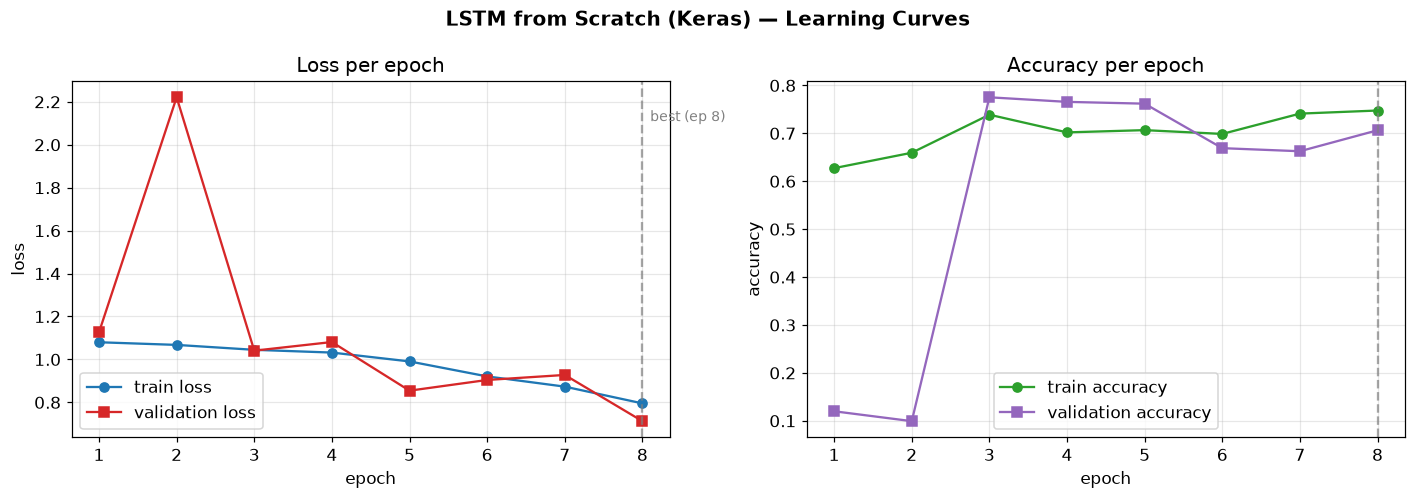

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))

# --- loss ---
ax1.plot(epochs, train_loss, "o-", label="train loss", color="#1f77b4")
ax1.plot(epochs, val_loss, "s-", label="validation loss", color="#d62728")
ax1.axvline(best_epoch, ls="--", color="gray", alpha=0.7)
ax1.text(best_epoch + 0.1, max(val_loss) * 0.95, f"best (ep {best_epoch})", fontsize=9, color="gray")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")
ax1.set_title("Loss per epoch"); ax1.legend()

# --- accuracy ---
if train_acc and val_acc:
    ax2.plot(epochs, train_acc, "o-", label="train accuracy", color="#2ca02c")
    ax2.plot(epochs, val_acc, "s-", label="validation accuracy", color="#9467bd")
    ax2.axvline(best_epoch, ls="--", color="gray", alpha=0.7)
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy")
    ax2.set_title("Accuracy per epoch"); ax2.legend()

fig.suptitle("LSTM from Scratch (Keras) — Learning Curves", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "lstm_keras_learning_curves.png", bbox_inches="tight")
plt.show()

## 3. Confusion Matrix

The confusion matrix evaluates the performance of the classification model on the unseen test set. It visualizes the true positives and false positives across the three sentiment classes: negative, neutral, and positive.

Loading and normalizing data from parquet (Silver) and JSON (Gold)...
Computing class weights for training...
Fitting tokenizer and converting texts to sequences...
Applying padding to standardize sequences to 200 tokens...
Data pipeline completed successfully.

model in: c:\Users\Andro\Documents\UD\2026-3\Machine_Learning\JulianCelisCreator-ML-NLP-Sentimental-Analysis-W2\checkpoints\model_best_LSTM.keras
Generando predicciones sobre el conjunto de prueba...
200/200 [==============================] - 3s 16ms/step


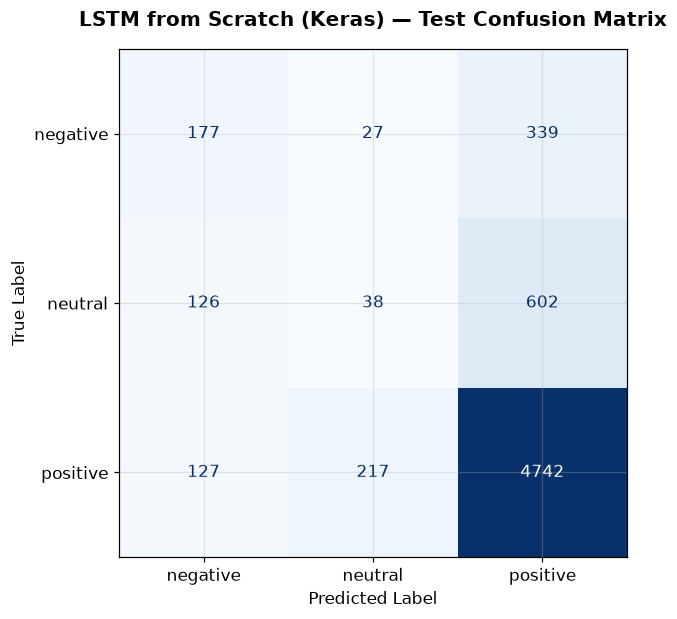

In [7]:
#confusion matrix

import sys
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tf_keras.models import load_model

if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

# use the function to use the val data
from src.LSTM.data import prepare_lstm_data

# 1. Execute the pipeline
data_dict = prepare_lstm_data()
X_val = data_dict["x_val"]
y_true = data_dict["y_val"] 

# 2. use the best model
model_path = ROOT / "checkpoints" / "model_best_LSTM.keras"
print(f"model in: {model_path}")
model = load_model(model_path)

# 3. predict
print("Generando predicciones sobre el conjunto de prueba...")
y_pred_probs = model.predict(X_val)
y_pred = np.argmax(y_pred_probs, axis=1)

# 4. Graficar la Matriz de Confusión
LABELS = ["negative", "neutral", "positive"]
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS)
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)

ax.set_title("LSTM from Scratch (Keras) — Test Confusion Matrix", fontweight="bold", pad=15)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

# Guardar y mostrar la figura
fig.savefig(FIG / "lstm_keras_confusion_matrix.png", bbox_inches="tight")
plt.show()